In [ ]:
import argparse
import contextlib
import importlib
import logging
import os
import sys
import time
import traceback
from pathlib import Path
 
import numpy as np
import pandas as pd
from flwr.simulation import run_simulation
 
import config
import fl_basic4 as fl            # <- ganti ke fl_basic4 bila nama file-mu itu
importlib.reload(fl)                # supaya perubahan file langsung terbaca
from dataset import DROP_COLS, TARGET
from model import build_model
 
# %%
# ============================================================
# 0. KONFIGURASI RUNNER
# ============================================================
CLIENT_DIR = Path(r'C:\Users\s2\Documents\FIXRKI\bfprssprep\split\clients')
 
# Hanya varian pairwise (hasil tuning temperature x data_influence)
ALGOS = list(fl.COMPARE_ALGOS)
 
# Pembanding untuk uji berpasangan: pairwise murni (tanpa pengaruh jumlah data)
BASELINE = 'fedpairwise_t0.01_d0.0'
 
ORIG_OUT_DIR = Path(config.OUT_DIR)      # folder induk output = ORIG_OUT_DIR.parent
ORIG_SEED = int(config.SEED)
 
# ATUR SEED DI SINI. Tiap varian dijalankan sekali per seed.
#   cepat                 : SEEDS = [42]
#   bukti tidak kebetulan : SEEDS = [0, 1, 2, 3, 4]
SEEDS = [42, 22, 1]
 
METRIC_COLS = ['acc', 'prec', 'rec', 'f1', 'auc',
               'f1_macro', 'f1_std_klien', 'total_MB', 'waktu_s']
 
# --- Peredam log (hindari limit context/output) ---
LOG_FLWR = "fl_run.log"
LOG_PRINTS = "fl_prints.log"
VERBOSE = False                  # True = tampilkan semuanya (--verbose)
 
 
def setup_flwr_logging():
    """Console Flower hanya WARNING+; detail penuh ke file. Aman dipanggil berulang."""
    lg = logging.getLogger("flwr")
    for h in lg.handlers:
        if not isinstance(h, logging.FileHandler):
            h.setLevel(logging.WARNING)
    if not any(isinstance(h, logging.FileHandler) for h in lg.handlers):
        fh = logging.FileHandler(LOG_FLWR, encoding="utf-8")
        fh.setLevel(logging.INFO)
        fh.setFormatter(logging.Formatter("%(asctime)s %(levelname)s %(message)s"))
        lg.addHandler(fh)
    lg.setLevel(logging.INFO)
 
 
@contextlib.contextmanager
def quiet(logfile=None):
    """Alihkan print() ke file. Dinonaktifkan bila VERBOSE."""
    if VERBOSE:
        yield
        return
    with open(logfile or LOG_PRINTS, "a", encoding="utf-8") as f, \
            contextlib.redirect_stdout(f):
        yield
 
 
setup_flwr_logging()

In [3]:

# %%
# ============================================================
# 1. DATASET, MODUL & RINGKASAN DATA
# ============================================================
def setup_dataset():
    """Arahkan config ke folder dataset dan buang cache data lama."""
    if not CLIENT_DIR.is_dir():
        sys.exit(f"Folder dataset tidak ditemukan: {CLIENT_DIR}")
    config.CLIENT_DIR = CLIENT_DIR
    # Worker Ray membaca config.py sendiri, jadi folder dikirim lewat env var.
    os.environ['FL_CLIENT_DIR'] = str(CLIENT_DIR)
    try:
        import ray
        if ray.is_initialized():
            ray.shutdown()
    except ImportError:
        pass
    clear = getattr(fl.load_data, 'cache_clear', None)
    if clear:
        clear()
    n_item = sum(1 for _ in CLIENT_DIR.iterdir())
    print(f"Dataset : {CLIENT_DIR} ({n_item} item)")
 
 
def show_modules():
    print(f"Modul FL: {fl.__name__} ({Path(fl.__file__).name})")
    cls = getattr(fl, 'FedCosinePairwise', None)
    if cls is not None:
        print(f"Agregasi pairwise dari modul: {cls.__module__}")
    print("Varian  :")
    for a in ALGOS:
        v = fl.PAIRWISE_VARIANTS[a]
        print(f"   {a:<26} temperature={v['temperature']:<5} "
              f"data_influence={v['data_influence']}")
    print(f"Baseline uji berpasangan: {BASELINE}")
 
 
def available_algos(algos):
    """Buang varian yang tidak dikenal oleh modul fl."""
    known = getattr(fl, 'ALGOS', algos)
    ok = [a for a in algos if a in known]
    skip = [a for a in algos if a not in ok]
    if skip:
        print(f"[lewati] tidak ada di {fl.__name__}.ALGOS: {skip}")
    return ok
 
 
def data_summary():
    clients, scaler, feature_names = fl.load_data()
    n_clients = len(clients)
    n_fitur = fl.get_in_dim()
    assert n_fitur == len(feature_names), "Jumlah fitur tidak cocok dengan nama fitur"
 
    print("=" * 50)
    print(f"Jumlah client (state) : {n_clients}")
    print(f"Daftar state          : {fl.state_list()}")
    print(f"Target                : {TARGET}")
    print(f"Kolom dibuang         : {DROP_COLS}")
    print(f"Jumlah fitur          : {n_fitur}")
    print(f"Jumlah ronde          : {config.NUM_ROUNDS}")
    print(f"Client dilatih/ronde  : "
          f"{max(1, round(config.FRACTION_FIT * n_clients))} dari {n_clients}")
    print(f"Local epochs          : {config.LOCAL_EPOCHS}")
    print("=" * 50)
    if VERBOSE or n_fitur <= 30:
        for i, nama in enumerate(feature_names, 1):
            print(f"{i:>3}. {nama}")
    else:
        print(f"(daftar {n_fitur} fitur disembunyikan; gunakan --verbose)")
 
    rows = {st: {
        'n_train':   len(c['y_train_t']),
        'n_val':     len(c['y_val_t']),
        'n_test':    len(c['y_test_t']),
        'pos_train': int(c['y_train_t'].sum()),
        'pos_val':   int(c['y_val_t'].sum()),
        'pos_test':  int(c['y_test_t'].sum()),
    } for st, c in clients.items()}
 
    ringkas = pd.DataFrame(rows).T
    ringkas.index.name = 'state'
    for s in ('train', 'val', 'test'):
        ringkas[f'pos_{s}_%'] = (100 * ringkas[f'pos_{s}'] / ringkas[f'n_{s}']).round(2)
 
    total = ringkas[[c for c in ringkas.columns if not c.endswith('%')]].sum()
    for s in ('train', 'val', 'test'):
        total[f'pos_{s}_%'] = round(100 * total[f'pos_{s}'] / total[f'n_{s}'], 2)
    ringkas.loc['TOTAL'] = total
 
    print("\nRingkasan per client:")
    print(ringkas.to_string())
 
    total_train = sum(len(c['y_train_t']) for c in clients.values())
    print("\nscaler.n_samples_seen_ vs total train:",
          scaler.n_samples_seen_, total_train, "(harus sama)")
    return n_clients
 
 
# %%
# ============================================================
# 2. JALANKAN SATU (VARIAN, SEED)
# ============================================================
def run_algo(algo, seed, n_clients, out_root):
    """
    Simulasi FL untuk satu varian & seed.
    Output: out_root/seed_<seed>/<algo>/
 
    server_fn (fl_running1) menulis ke fl.BASE_OUT/<algo> untuk varian pairwise,
    jadi BASE_OUT diarahkan ke folder seed supaya antar-seed tidak saling menimpa.
    """
    config.SEED = seed
    os.environ['FL_SEED'] = str(seed)               # dibaca fl.get_seed()
    seed_dir = out_root / f'seed_{seed}'
    fl.BASE_OUT = seed_dir                          # dipakai fl.server_fn
    config.OUT_DIR = seed_dir / algo                # sama dengan yang diset server_fn
    config.ensure_out_dir()
    for nama in ('final_params.npz', 'ronde_log.csv', 'client_error.log'):
        (config.OUT_DIR / nama).unlink(missing_ok=True)
 
    print(f"\n########## {algo} | seed {seed} ##########")   # tetap tampil
    setup_flwr_logging()                  # run_simulation bisa menambah handler baru
    with quiet():
        print(f"\n##### {algo} | seed {seed} #####")          # masuk file log
        run_simulation(
            server_app=fl.make_server_app(algo),
            client_app=fl.make_client_app(),
            num_supernodes=n_clients,
            backend_config={"client_resources": {"num_cpus": 1, "num_gpus": 0.0}},
        )
 
 
def load_global_model():
    """Bangun model global dari final_params.npz di config.OUT_DIR saat ini."""
    path = Path(config.OUT_DIR) / 'final_params.npz'
    if not path.exists():
        raise FileNotFoundError(
            f"{path} tidak ada: simulasi gagal sebelum ada ronde yang selesai. "
            f"Cek {Path(config.OUT_DIR) / 'client_error.log'}")
    d = np.load(path)
    w = [d[f'arr_{i}'] for i in range(len(d.files))]
    m = build_model(fl.get_in_dim(), seed=config.SEED).to(config.DEVICE)
    fl.set_weights(m, w)
    return m
 
 
def run_single(algo, seeds, n_clients, out_root):
    try:
        for seed in seeds:
            run_algo(algo, seed, n_clients, out_root)
 
            rep, ronde = fl.bandwidth_report(verbose=VERBOSE)
            if VERBOSE:
                print(ronde.round(4).to_string(index=False))
            else:
                print(ronde.round(4).tail(3).to_string(index=False))
 
            model = load_global_model()
            df_test = fl.evaluate_on_clients(model, split='test')
            if VERBOSE:
                print(df_test.round(4).to_string())
            print(fl.summarize(df_test).round(4).to_string())
            print("Pooled:", fl.evaluate_pooled(model, split='test'))
    finally:
        config.SEED = ORIG_SEED
 


Modul FL: fl_basic4 (fl_basic4.py)
Agregasi pairwise dari modul: aggregation4
Varian  :
   fedpairwise_t0.1_d0.0      temperature=0.1   data_influence=0.0
   fedpairwise_t0.1_d0.3      temperature=0.1   data_influence=0.3
   fedpairwise_t0.1_d0.5      temperature=0.1   data_influence=0.5
   fedpairwise_t0.01_d0.0     temperature=0.01  data_influence=0.0
   fedpairwise_t0.01_d0.3     temperature=0.01  data_influence=0.3
   fedpairwise_t0.01_d0.5     temperature=0.01  data_influence=0.5
Baseline uji berpasangan: fedpairwise_t0.01_d0.0
Dataset : C:\Users\s2\Documents\FIXRKI\bfprssprep\split\clients (45 item)
Jumlah client (state) : 44
Daftar state          : [1, 2, 4, 5, 8, 10, 11, 12, 13, 15, 16, 17, 18, 19, 20, 22, 23, 24, 25, 26, 27, 29, 30, 31, 33, 34, 35, 36, 37, 38, 39, 40, 41, 44, 45, 46, 48, 49, 50, 51, 53, 54, 55, 56]
Target                : _michd
Kolom dibuang         : ['iyear', '_state', 'cvdinfr4', 'cvdcrhd4']
Jumlah fitur          : 69
Jumlah ronde          : 10
Client dila

[selesai] fedpairwise_t0.1_d0.0 s42: F1 test 0.4675 | AUC 0.7392 | 34.99 MB | 72.0 s

########## fedpairwise_t0.1_d0.3 | seed 42 ##########


[selesai] fedpairwise_t0.1_d0.3 s42: F1 test 0.4677 | AUC 0.7386 | 34.99 MB | 84.3 s

########## fedpairwise_t0.1_d0.5 | seed 42 ##########


[selesai] fedpairwise_t0.1_d0.5 s42: F1 test 0.4676 | AUC 0.7381 | 34.99 MB | 129.8 s

########## fedpairwise_t0.01_d0.0 | seed 42 ##########


[selesai] fedpairwise_t0.01_d0.0 s42: F1 test 0.4666 | AUC 0.7394 | 34.99 MB | 129.5 s

########## fedpairwise_t0.01_d0.3 | seed 42 ##########


...

[selesai] fedpairwise_t0.1_d0.3 s1: F1 test 0.4653 | AUC 0.7381 | 34.99 MB | 71.5 s

########## fedpairwise_t0.1_d0.5 | seed 1 ##########


[selesai] fedpairwise_t0.1_d0.5 s1: F1 test 0.4640 | AUC 0.7376 | 34.99 MB | 68.5 s

########## fedpairwise_t0.01_d0.0 | seed 1 ##########


[selesai] fedpairwise_t0.01_d0.0 s1: F1 test 0.4651 | AUC 0.7391 | 34.99 MB | 69.4 s

########## fedpairwise_t0.01_d0.3 | seed 1 ##########


[selesai] fedpairwise_t0.01_d0.3 s1: F1 test 0.4654 | AUC 0.7393 | 34.99 MB | 69.7 s

########## fedpairwise_t0.01_d0.5 | seed 1 ##########


[selesai] fedpairwise_t0.01_d0.5 s1: F1 test 0.4649 | AUC 0.7388 | 34.99 MB | 70.6 s

PERBANDINGAN VARIAN PAIRWISE  (rata-rata ± std antar seed; urut F1)
                        n_seed              acc             prec              rec               f1              auc         f1_macro     f1_std_klien      total_MB        waktu_s
algoritma                                                                                                                                                                         
fedpairwise_t0.01_d0.3       3  0.6962 ± 0.0045  0.3687 ± 0.0032  0.6349 ± 0.0091  0.4664 ± 0.0010  0.7392 ± 0.0005  0.4633 ± 0.0008  0.0428 ± 0.0013  34.99 ± 0.00  89.23 ± 33.92
fedpairwise_t0.01_d0.5       3  0.6960 ± 0.0053  0.3686 ± 0.0043  0.6351 ± 0.0079  0.4664 ± 0.0021  0.7388 ± 0.0005  0.4633 ± 0.0014  0.0420 ± 0.0012  34.99 ± 0.00  89.20 ± 34.23
fedpairwise_t0.1_d0.0        3  0.6963 ± 0.0054  0.3686 ± 0.0042  0.6336 ± 0.0094  0.4660 ± 0.0014  0.7387 ± 0.0005  0.4631 ± 0.00

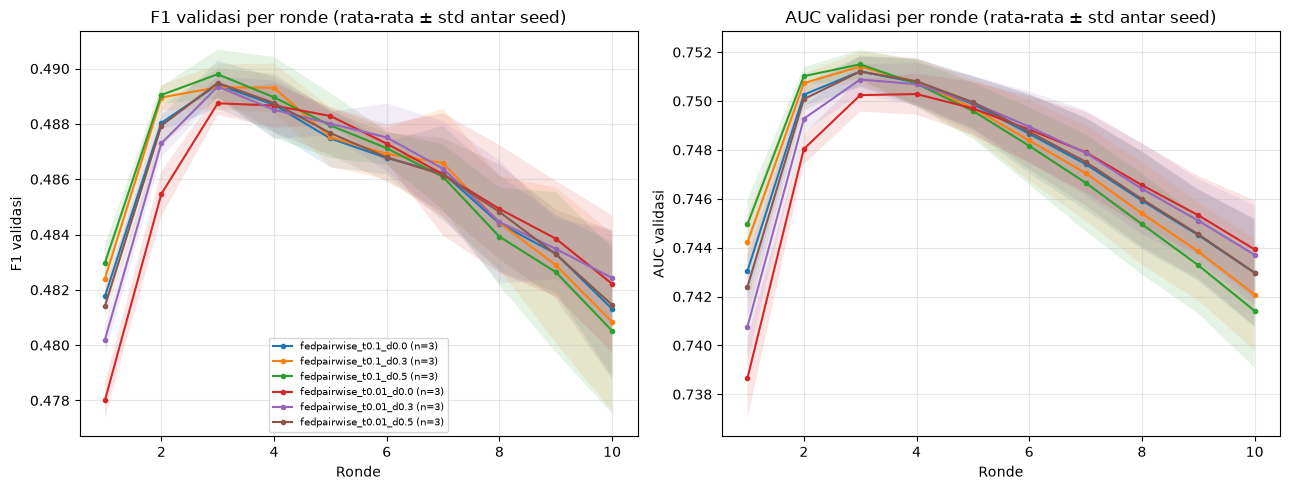

In [4]:
 
# %%
# ============================================================
# 3. KOMPARASI ANTAR VARIAN (multi-seed)
# ============================================================
def collect_result(secs):
    """Kumpulkan hasil run yang baru selesai (config.OUT_DIR menunjuk ke run itu)."""
    model = load_global_model()
    pooled = fl.evaluate_pooled(model, split='test')
    df_test = fl.evaluate_on_clients(model, split='test')
    ronde = pd.read_csv(Path(config.OUT_DIR) / 'ronde_log.csv')
    bw, _ = fl.bandwidth_report(verbose=False)
 
    f1 = ronde['f1'].astype(float)
    if f1.notna().any():
        best = f1.idxmax()
        val_best, best_round = float(f1[best]), int(ronde.loc[best, 'round'])
    else:
        val_best, best_round = float('nan'), -1
 
    row = {
        **{k: float(v) for k, v in pooled.items()},      # metrik test gabungan
        'f1_macro':       float(df_test['f1'].mean()),
        'f1_std_klien':   float(df_test['f1'].std()),
        'val_f1_akhir':   float(f1.iloc[-1]),
        'val_f1_terbaik': val_best,
        'ronde_terbaik':  best_round,
        'total_MB':       float(bw['total_MB']),
        'waktu_s':        round(secs, 1),
    }
    return row, df_test['f1'], ronde
 
 
def _fmt(mean, std, n, nd=4):
    if n < 2 or pd.isna(std):
        return f"{mean:.{nd}f}"
    return f"{mean:.{nd}f} ± {std:.{nd}f}"
 
 
def summarize_seeds(per_seed):
    """Rata-rata & simpangan antar seed untuk tiap varian."""
    cols = [c for c in METRIC_COLS if c in per_seed.columns]
    g = per_seed.groupby(level='algoritma')[cols]
    mean, std = g.mean(), g.std()
    n = g.size().rename('n_seed')
 
    num = pd.concat({'mean': mean, 'std': std}, axis=1)
    num.columns = [f'{c}_{stat}' for stat, c in num.columns]
    num.insert(0, 'n_seed', n)
    num = num.sort_values('f1_mean', ascending=False)
 
    tampil = pd.DataFrame(index=num.index)
    tampil['n_seed'] = num['n_seed']
    for c in cols:
        nd = 2 if c in ('total_MB', 'waktu_s') else 4
        tampil[c] = [_fmt(num.loc[a, f'{c}_mean'], num.loc[a, f'{c}_std'],
                          int(num.loc[a, 'n_seed']), nd) for a in num.index]
    return num, tampil
 
 
def _pvalue(d):
    """Uji-t berpasangan (selisih d terhadap 0). NaN bila tidak bisa dihitung."""
    if len(d) < 3 or float(d.std()) == 0.0:
        return float('nan')
    try:
        from scipy import stats
    except ImportError:
        return float('nan')
    return float(stats.ttest_1samp(d, 0.0).pvalue)
 
 
def paired_vs_baseline(per_seed, baseline, metrics=('f1', 'auc')):
    """Selisih tiap varian terhadap baseline pada seed yang sama."""
    algos = list(per_seed.index.get_level_values('algoritma').unique())
    if baseline not in algos:
        return None
    base = per_seed.xs(baseline, level='algoritma')
    out = []
    for algo in algos:
        if algo == baseline:
            continue
        cur = per_seed.xs(algo, level='algoritma')
        seeds = base.index.intersection(cur.index)
        if len(seeds) == 0:
            continue
        row = {'algoritma': algo, 'n_seed': len(seeds)}
        for m in metrics:
            d = (cur.loc[seeds, m] - base.loc[seeds, m]).astype(float)
            row[f'd{m}_mean'] = float(d.mean())
            row[f'd{m}_std'] = float(d.std()) if len(d) > 1 else float('nan')
            row[f'{m}_menang'] = f"{int((d > 0).sum())}/{len(d)}"
            row[f'{m}_p'] = _pvalue(d)
        out.append(row)
    return pd.DataFrame(out).set_index('algoritma') if out else None
 
 
def plot_curves(kurva, out_path):
    """F1 & AUC validasi per ronde: rata-rata antar seed, pita = ± std."""
    try:
        import matplotlib
        if 'ipykernel' not in sys.modules:
            matplotlib.use('Agg')
        import matplotlib.pyplot as plt
    except ImportError:
        print("[lewati grafik] matplotlib belum terpasang (pip install matplotlib)")
        return
 
    per_algo = {}
    for (algo, _), ronde in kurva.items():
        per_algo.setdefault(algo, []).append(ronde)
 
    fig, axes = plt.subplots(1, 2, figsize=(13, 5))
    for ax, col, judul in zip(axes, ('f1', 'auc'), ('F1 validasi', 'AUC validasi')):
        for algo, rs in per_algo.items():
            m = pd.concat([r.set_index('round')[col] for r in rs], axis=1)
            mu, sd = m.mean(axis=1), m.std(axis=1)
            ax.plot(mu.index, mu.values, marker='o', ms=3,
                    label=f'{algo} (n={len(rs)})')
            if len(rs) > 1:
                ax.fill_between(mu.index, (mu - sd).values, (mu + sd).values, alpha=0.12)
        ax.set_xlabel('Ronde')
        ax.set_ylabel(judul)
        ax.set_title(f'{judul} per ronde (rata-rata ± std antar seed)')
        ax.grid(alpha=0.3)
    axes[0].legend(fontsize=7)
    fig.tight_layout()
    fig.savefig(out_path, dpi=150)
    print(f"Grafik disimpan: {out_path}")
    if 'ipykernel' in sys.modules:
        plt.show()
    else:
        plt.close(fig)
 
 
def run_compare(algos, seeds, n_clients, out_root):
    rows, f1_klien, kurva = {}, {}, {}
    total_run = len(algos) * len(seeds)
    print(f"\nKomparasi: {len(algos)} varian x {len(seeds)} seed = {total_run} run")
    print(f"Seed: {seeds}")
 
    try:
        for seed in seeds:                 # seed di luar: hasil parsial tetap seimbang
            for algo in algos:
                t0 = time.perf_counter()
                try:
                    run_algo(algo, seed, n_clients, out_root)
                    row, f1c, ronde = collect_result(time.perf_counter() - t0)
                except Exception:
                    print(f"[GAGAL] {algo} seed {seed}:\n{traceback.format_exc()}")
                    continue
                key = (algo, seed)
                rows[key], f1_klien[key], kurva[key] = row, f1c, ronde
                print(f"[selesai] {algo} s{seed}: F1 test {row['f1']:.4f} | "
                      f"AUC {row['auc']:.4f} | {row['total_MB']:.2f} MB | "
                      f"{row['waktu_s']} s")
    finally:
        config.SEED = ORIG_SEED
 
    if not rows:
        sys.exit("Tidak ada run yang berhasil.")
 
    idx = pd.MultiIndex.from_tuples(list(rows.keys()), names=['algoritma', 'seed'])
    per_seed = pd.DataFrame(list(rows.values()), index=idx)
 
    num, tampil = summarize_seeds(per_seed)
    berpasangan = paired_vs_baseline(per_seed, BASELINE)
 
    per_klien = pd.DataFrame({
        algo: pd.concat([f1_klien[k] for k in f1_klien if k[0] == algo], axis=1).mean(axis=1)
        for algo in num.index
    })
    per_klien.loc['MAKRO'] = per_klien.mean()
 
    print("\n" + "=" * 70)
    print("PERBANDINGAN VARIAN PAIRWISE  (rata-rata ± std antar seed; urut F1)")
    print("=" * 70)
    print(tampil.to_string())
 
    print("\nHasil per seed (F1 | AUC test gabungan):")
    print(per_seed[['f1', 'auc']].round(4).unstack('seed').to_string())
 
    if berpasangan is not None:
        print(f"\nSelisih terhadap {BASELINE} pada seed yang sama "
              f"(positif = lebih baik dari {BASELINE}):")
        print(berpasangan.round(4).to_string())
        if int(berpasangan['n_seed'].min()) < 5:
            print("Catatan: dengan <5 seed uji-t lemah; lihat kolom *_menang dan "
                  "konsistensi arah selisih, jangan hanya bergantung pada p-value.")
    elif len(seeds) > 1:
        print(f"\n[uji berpasangan dilewati] baseline '{BASELINE}' tidak ikut/gagal.")
 
    print("\nF1 test per state (rata-rata antar seed):")
    print(per_klien.round(4).to_string())
 
    print(f"\nTerbaik F1 (rata-rata)    : {num['f1_mean'].idxmax()}")
    print(f"Terbaik AUC (rata-rata)   : {num['auc_mean'].idxmax()}")
    if len(seeds) > 1:
        print(f"Paling stabil antar seed  : {num['f1_std'].idxmin()} (std F1 terkecil)")
    print(f"Paling merata antar state : {num['f1_std_klien_mean'].idxmin()}")
 
    out_root.mkdir(parents=True, exist_ok=True)
    per_seed.to_csv(out_root / 'perbandingan_per_seed.csv')
    num.to_csv(out_root / 'perbandingan_ringkasan.csv')
    per_klien.to_csv(out_root / 'perbandingan_f1_per_client.csv')
    if berpasangan is not None:
        berpasangan.to_csv(out_root / 'perbandingan_berpasangan.csv')
    print(f"\nCSV disimpan di: {out_root}")
    plot_curves(kurva, out_root / 'kurva_validasi.png')
    return per_seed, num
 
 
# %%
# ============================================================
# 4. ENTRY POINT  (guard wajib untuk Ray/multiprocessing di Windows)
# ============================================================
def main(argv=None):
    global VERBOSE
    ap = argparse.ArgumentParser(description="Simulasi FL: komparasi varian FedPairwise")
    ap.add_argument('--algo', default=None, choices=ALGOS,
                    help="jalankan satu varian saja (tanpa komparasi)")
    ap.add_argument('--compare', action='store_true',
                    help="komparasi (default bila --algo tidak diberikan)")
    ap.add_argument('--algos', nargs='+', choices=ALGOS, default=ALGOS,
                    help="daftar varian untuk komparasi")
    ap.add_argument('--seeds', nargs='+', type=int, default=None,
                    help="timpa SEEDS di atas, mis. --seeds 0 1 2 3 4")
    ap.add_argument('--info', action='store_true',
                    help="hanya tampilkan ringkasan data")
    ap.add_argument('--verbose', action='store_true',
                    help="tampilkan semua log/print di layar (tanpa peredam)")
    # parse_known_args: abaikan argumen asing (mis. --f=kernel.json dari Jupyter)
    args, _ = ap.parse_known_args(argv)
    VERBOSE = args.verbose
 
    seeds = list(dict.fromkeys(args.seeds)) if args.seeds else list(dict.fromkeys(SEEDS))
 
    show_modules()
    setup_dataset()
    n_clients = data_summary()
    if args.info:
        return
 
    out_root = ORIG_OUT_DIR.parent
 
    if args.algo and not args.compare:
        run_single(args.algo, seeds, n_clients, out_root)
    else:
        run_compare(available_algos(args.algos), seeds, n_clients, out_root)
 
 
if __name__ == '__main__':
    main()